# Experimento A/B en página de inicio

*Proyecto guiado del programa de Análisis de Datos de TripleTen (Sprint 9). El caso, el dataset y los pasos vienen del curso; el análisis, la interpretación y las recomendaciones son míos.*

Evalúo un experimento A/B hecho sobre una página de inicio (landing page) con dos versiones, A y B, para respaldar con datos una decisión de negocio: qué versión conviene dejar.

El archivo `landing_experiment.csv` tiene usuarios expuestos a una de las dos versiones, con su región, dispositivo, fuente de tráfico, tipo de usuario, si convirtieron y cuánto gastaron. El análisis sigue este orden:

1. Explorar y validar los datos.
2. Comparar el gasto promedio por usuario entre A y B.
3. Comparar la tasa de conversión entre A y B.
4. Revisar la relación entre la fuente de tráfico y la conversión.
5. Revisar la relación entre el tipo de usuario y la conversión.
6. Visualizar los resultados.
7. Resumir los hallazgos para negocio.

Para comparar las páginas aplico pruebas estadísticas y al final recomiendo una versión.

## Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [328]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

In [329]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [330]:
# mostrar las primeras 5 filas
df.head(5)

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [331]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


El dataset no tiene valores ausentes, así que no hace falta imputar ni eliminar registros.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id`: Identificador único del usuario
- `date`: Fecha en la que el usuario fue expuesto a la página
- `landing`: Versión de la página mostrada al usuario
- `region`: Región geográfica del usuario
- `dispositivo`: Tipo de dispositivo utilizado por el usuario
- `traffic_source`: Canal por el que llegó el usuario
- `user_type`: Tipo de usuario según historial previo
- `converted`: Indica si el usuario realizó una conversión
- `gasto`: Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Identifico las variables clave del experimento y reviso que estén bien definidas, completas y que sean consistentes.

**`user_id`:** reviso los identificadores de usuario.

In [332]:
df["user_id"].unique()

array(['26f3052e-8500-44ea-8fff-06de65258abb',
       '92378c09-4bbf-40c7-945e-82b84f392d22',
       'a4397360-40e5-45d6-a7ff-dcb4da2c9a1f', ...,
       '02fbb5df-c7a7-4286-a8bc-97bd741fa2d7',
       '299ad979-d990-458f-81a8-b9fd21a023b0',
       'fabb98e7-0f74-4baf-9a32-ac8e09936787'], dtype=object)

**`date`:** rango de fechas del experimento.

In [333]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [334]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01
Fecha máxima: 2026-01-28


El experimento corrió del 1 al 28 de enero de 2026.

**Variable `gasto` (numérica)**

In [335]:
# Resumen estadístico
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [336]:
# Resumen estadístico de usuarios que se convirtieron
usuarios_convertidos = df[df["converted"] == 1]
usuarios_convertidos["gasto"].describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

El gasto es 0 para quienes no convirtieron, por eso la mediana y el cuartil 75 son 0. Entre los 5,706 usuarios que sí convirtieron, el gasto promedio es de 65.37.

**Variables categóricas:** verifico las categorías esperadas del experimento (A y B) y las de las demás variables.

In [337]:
# Explorar variables categóricas y cómo se distribuyen
variables_categoricas = ["landing","region","dispositivo","traffic_source","user_type"]
print("\nConteo de categorías:")
for columna in variables_categoricas:
    print(f"\n{columna}:")
    print(df[columna].value_counts())


Conteo de categorías:

landing:
B    20018
A    19982
Name: landing, dtype: int64

region:
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64

dispositivo:
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64

traffic_source:
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

user_type:
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64


Todas las columnas tienen valores esperados. No hay categorías mal escritas, duplicadas por diferencias de formato ni valores adicionales que necesiten corrección.

## Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Evalúo si hay diferencias estadísticamente significativas en el gasto promedio de los usuarios que se convirtieron en clientes entre la página A y la B, para saber qué versión genera más valor económico.

In [338]:
# Gasto por versión
gasto_A = df[(df["landing"]=="A") & (df["converted"] ==1)]["gasto"]
gasto_B = df[(df["landing"]=="B") & (df["converted"] ==1)]["gasto"]

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

In [339]:
print("Gasto promedio A:", gasto_A.mean())
print("Gasto promedio B:", gasto_B.mean())

Gasto promedio A: 61.0865724522293
Gasto promedio B: 68.74536005009392


### Prueba t de Welch

Uso la variante de Welch (`equal_var=False`) porque no asumo varianzas iguales entre las dos páginas.

**Hipótesis:**
- H₀: no hay una diferencia estadísticamente significativa en el gasto promedio de los usuarios convertidos entre la página A y la B; el gasto promedio de ambas es igual.
- H₁: sí hay una diferencia estadísticamente significativa en el gasto promedio de los usuarios convertidos entre las dos páginas.

In [340]:
# Aplicar prueba
from scipy.stats import ttest_ind
resultado = ttest_ind(gasto_A, gasto_B, equal_var= False )

# Visualizar resultados
print(f"Estadístico : {resultado.statistic:.4f}")
print(f"Valor p: {resultado.pvalue:.4f}")

Estadístico : -9.4810
Valor p: 0.0000


### Conclusión e interpretación

**Decisión:** se rechaza H₀, porque el valor p (p < 0.001) es menor que el nivel de significancia de 0.05. Hay evidencia estadísticamente significativa de que el gasto promedio de los usuarios convertidos es distinto entre la página A y la B.

**Interpretación de negocio:** los usuarios convertidos que vieron la página B gastan más en promedio: 68.74 contra 61.08 de la página A, una diferencia de unas 7.66 unidades monetarias por usuario convertido. El resultado de la prueba indica que la diferencia no parece deberse solo a la variabilidad aleatoria, así que la página B genera más valor económico por usuario convertido.

Con este indicador la página B se ve mejor, pero la decisión final debe complementarse con la tasa de conversión: una página puede generar más gasto por cliente y convertir a una proporción menor de usuarios.

## Paso 3: Comparar la tasa de conversión entre la página A y la B

Evalúo si hay diferencias estadísticamente significativas en la tasa de conversión entre las dos páginas, para saber qué versión convierte a más usuarios.

### Prueba z de dos proporciones

**Hipótesis:**
- H₀: no hay una diferencia estadísticamente significativa en la tasa de conversión entre los usuarios expuestos a la página A y los expuestos a la B; ambas páginas convierten igual.
- H₁: sí hay una diferencia estadísticamente significativa en la tasa de conversión entre las dos páginas.

In [341]:
# Número de usuarios convertidos por página
convercion_por_pagina = df.groupby("landing")["converted"].sum()

# Total de usuarios por página
total_por_pagina = df.groupby("landing")["converted"].count()

print("Usuarios convertidos por página:\n", convercion_por_pagina)
print("\nTotal de usuarios por página:\n", total_por_pagina)


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [342]:
tasa_A = convercion_por_pagina["A"] / total_por_pagina["A"]
tasa_B = convercion_por_pagina["B"] / total_por_pagina["B"]

print(f"Tasa de conversión A: {tasa_A:.2%}")
print(f"Tasa de conversión B: {tasa_B:.2%}")

Tasa de conversión A: 12.57%
Tasa de conversión B: 15.96%


In [343]:
# Aplicar prueba
from statsmodels.stats.proportion import proportions_ztest

convertidos = [convercion_por_pagina["A"], convercion_por_pagina["B"]]
totales = [total_por_pagina["A"], total_por_pagina["B"]]

resultado = proportions_ztest(convertidos, totales, alternative="two-sided")

# Visualizar resultados
print(f"Estadístico : {resultado[0]:.4f}")
print(f"Valor p: {resultado[1]:.4f}")

Estadístico : -9.6774
Valor p: 0.0000


### Conclusión e interpretación

**Decisión:** se rechaza H₀, porque el valor p (0.0000) es menor que 0.05. Hay evidencia estadísticamente significativa de una diferencia en las tasas de conversión de A y B.

**Interpretación de negocio:** la página B convierte más que la A, con 15.96 % frente a 12.57 %, una diferencia de 3.39 puntos porcentuales. B logra convertir una proporción mayor de usuarios en clientes y, con base en este experimento, tiene mejor desempeño en conversión.

## Paso 4: Relación entre la fuente de tráfico y la conversión

Reviso si hay una asociación estadísticamente significativa entre la fuente de tráfico (`traffic_source`) y la conversión (`converted`), para saber qué canales generan más conversiones.

### Prueba chi-cuadrada de independencia

**Hipótesis:**
- H₀: no hay asociación estadísticamente significativa entre `traffic_source` y `converted`; las dos variables son independientes.
- H₁: sí hay asociación entre `traffic_source` y `converted`; las variables no son independientes.

In [344]:
from scipy.stats import chi2_contingency
# Tabla de contingencia
tabla_contingencia = pd.crosstab(df["traffic_source"], df["converted"])

print("Tabla de contingencia:")
print(tabla_contingencia)

Tabla de contingencia:
converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549


In [345]:
# Aplicar prueba Chi-cuadrada
resultado = chi2_contingency(tabla_contingencia)

# Visualizar resultados
print(f"Estadístico : {resultado[0]:.4f}")
print(f"Valor p: {resultado[1]:.4f}")

Estadístico : 8.6621
Valor p: 0.0341


### Conclusión e interpretación

**Decisión:** se rechaza H₀, porque el valor p (0.0341) es menor que 0.05. Hay evidencia estadísticamente significativa de una asociación entre la fuente de tráfico y la conversión.

**Interpretación de negocio:** la tasa de conversión no es igual en todas las fuentes de tráfico, es decir, el canal por el que llegan los usuarios está relacionado con su probabilidad de convertir.

En número de conversiones el orden es Organic (2,480), Ads (1,759), Email (918) y Referral (549). Pero para saber qué canal convierte mejor no basta con comparar conversiones absolutas: hay que calcular la tasa de cada fuente sobre el total de usuarios de ese canal. Eso se hace en el Paso 6.

En conclusión, el canal de adquisición es un factor relevante para la conversión, y conviene identificar qué fuentes tienen las tasas más altas para orientar la estrategia de marketing.

## Paso 5: Relación entre el tipo de usuario y la conversión

Reviso si hay una asociación estadísticamente significativa entre el tipo de usuario (`user_type`) y la conversión (`converted`). Un usuario recurrente puede haber visitado antes sin convertir en esta ocasión, así que el objetivo es ver qué perfiles tienen más probabilidad de convertir en este contexto.

### Prueba chi-cuadrada de independencia

**Hipótesis:**
- H₀: no hay asociación estadísticamente significativa entre `user_type` y `converted`; las dos variables son independientes.
- H₁: sí hay asociación entre `user_type` y `converted`; las variables no son independientes.

In [346]:
from scipy.stats import chi2_contingency

# Tabla de contingencia
tabla_contingencia = pd.crosstab(df["user_type"], df["converted"])

print("Tabla de contingencia:")
print(tabla_contingencia)

Tabla de contingencia:
converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968


In [347]:
# Aplicar prueba Chi-cuadrada
resultado = chi2_contingency(tabla_contingencia)

# Visualizar resultados
print(f"Estadístico : {resultado[0]:.4f}")
print(f"Valor p: {resultado[1]:.4f}")

Estadístico : 0.5135
Valor p: 0.4736


### Conclusión e interpretación

**Decisión:** no se rechaza H₀, porque el valor p (0.4736) es mayor que 0.05. No hay evidencia estadística suficiente para afirmar que el tipo de usuario se asocia con la conversión.

**Interpretación de negocio:** en este contexto, ser usuario nuevo o recurrente no está relacionado de forma significativa con la probabilidad de convertir. Aunque el número de convertidos es distinto entre los dos grupos, la diferencia se explica por el tamaño de cada grupo y no es lo bastante grande para concluir que un tipo de usuario convierte mejor que el otro. Las tasas se calculan en el Paso 6.

El tipo de usuario no parece un factor determinante de la conversión en este experimento, y por eso no hay base estadística para enfocar la estrategia solo en usuarios nuevos o solo en recurrentes.

## Paso 6: Visualizar los resultados de las variables categóricas

Exploro visualmente la relación de `traffic_source` y `user_type` con la conversión, mostrando para cada categoría la cantidad absoluta de usuarios que convirtieron y no convirtieron, y su proporción. Así se ve tanto el volumen como la efectividad relativa de cada categoría, y se refuerzan los resultados de las pruebas.

### Relación entre la fuente de tráfico y la conversión

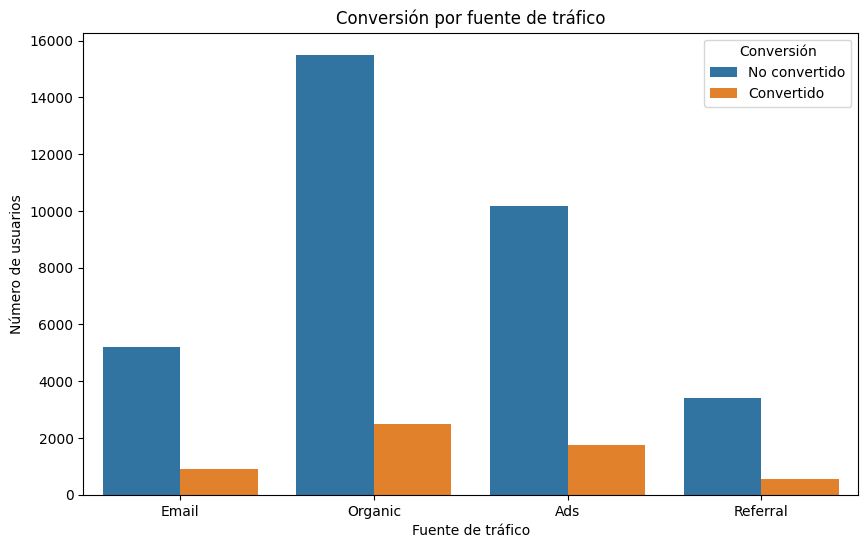

In [348]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.countplot(data=df, x="traffic_source",hue="converted")

plt.title("Conversión por fuente de tráfico")
plt.xlabel("Fuente de tráfico")
plt.ylabel("Número de usuarios")
plt.legend(title="Conversión", labels=["No convertido", "Convertido"])
plt.show()


Hay una asociación estadísticamente significativa entre la fuente de tráfico y la conversión (estadístico = 8.6621, p = 0.0341), así que el desempeño de conversión varía según el canal de adquisición. Organic es la fuente con más conversiones en volumen (2,480), seguida de Ads (1,759), Email (918) y Referral (549).

En cambio, no hay asociación estadísticamente significativa entre el tipo de usuario y la conversión (estadístico = 0.5135, p = 0.4736), por lo que no hay evidencia para decir que los usuarios nuevos y los recurrentes tengan probabilidades de conversión distintas.

In [349]:
proporcion_trafico = pd.crosstab(df["traffic_source"], df["converted"], normalize="index") * 100
print(proporcion_trafico)

converted               0          1
traffic_source                      
Ads             85.261835  14.738165
Email           85.007349  14.992651
Organic         86.212264  13.787736
Referral        86.118837  13.881163


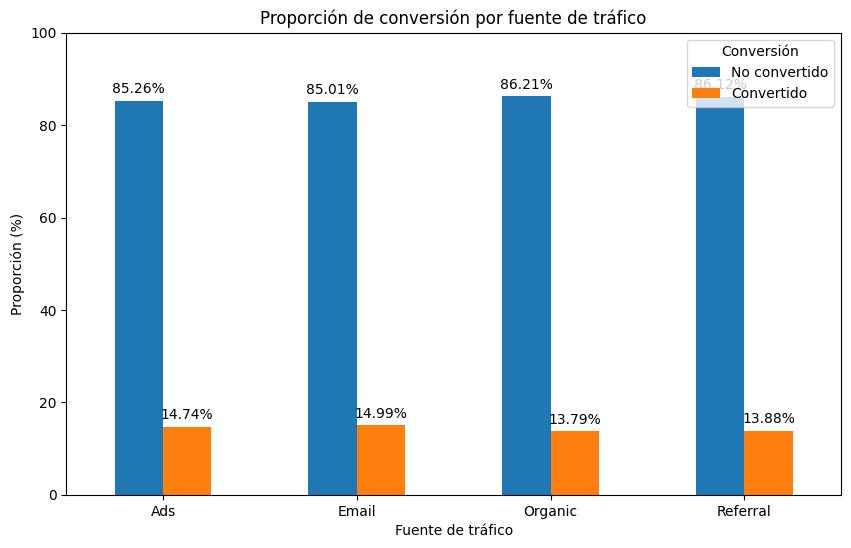

In [350]:
ax = proporcion_trafico.plot(kind="bar", figsize=(10, 6))

plt.title("Proporción de conversión por fuente de tráfico")
plt.xlabel("Fuente de tráfico")
plt.ylabel("Proporción (%)")
plt.xticks(rotation=0)
plt.legend(
    title="Conversión",
    labels=["No convertido", "Convertido"])
# Agregar etiquetas de porcentaje sobre cada barra
for container in ax.containers:
    for bar in container:
        altura = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2,
            altura + 1,
            f"{altura:.2f}%",
            ha="center",
            va="bottom")

plt.ylim(0, 100)
plt.show()

**Conclusión.** Email tiene la tasa de conversión más alta (14.99 %), seguido de Ads (14.74 %). Referral tiene 13.88 % y Organic la más baja (13.79 %). Las diferencias entre tasas son relativamente pequeñas, pero la prueba chi-cuadrada mostró una asociación estadísticamente significativa entre la fuente de tráfico y la conversión (estadístico = 8.6621, p = 0.0341), así que la fuente sí está relacionada con el comportamiento de conversión.

Hay que distinguir entre volumen y eficiencia: Organic genera más conversiones en cantidad porque tiene más usuarios, pero Email es el canal con mayor proporción de usuarios que convierten.

Resumen de hallazgos:
- Email: 14.99 % convierte, la mejor tasa.
- Ads: 14.74 %, la segunda mejor.
- Referral: 13.88 %.
- Organic: 13.79 %, la menor.
- Chi-cuadrada: p = 0.0341 < 0.05, hay asociación significativa entre la fuente de tráfico y la conversión.

### Relación entre el tipo de usuario y la conversión

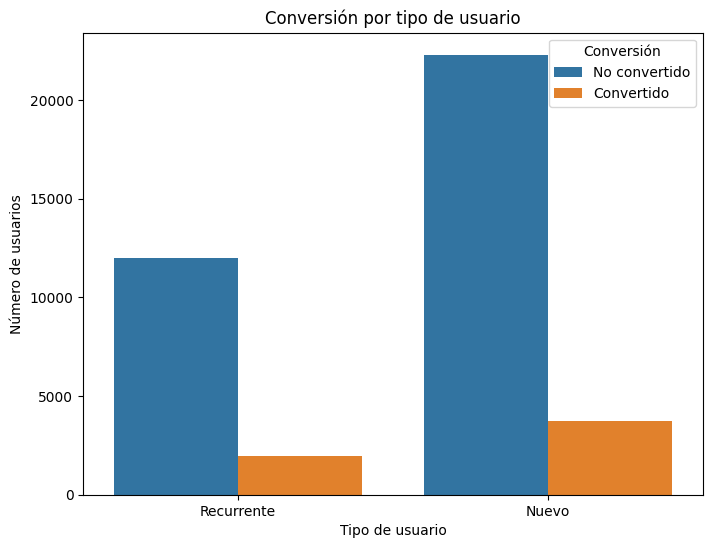

In [351]:
#Gráfico de barras agrupadas: usuarios convertidos y no convertidos
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.countplot(data=df, x="user_type",hue="converted")

plt.title("Conversión por tipo de usuario")
plt.xlabel("Tipo de usuario")
plt.ylabel("Número de usuarios")
plt.legend(
    title="Conversión",
    labels=["No convertido", "Convertido"])
plt.show()

**Conclusión.** La gráfica muestra que los usuarios nuevos concentran más conversiones en términos absolutos, pero las cantidades absolutas no sirven para saber qué tipo de usuario tiene más probabilidad de convertir, porque los grupos son de tamaños distintos. Para comparar el desempeño es mejor usar las proporciones.

Los usuarios nuevos tienen 3,738 conversiones y 22,295 no conversiones; los recurrentes, 1,968 conversiones y 11,999 no conversiones. El número absoluto de conversiones es mayor en los nuevos sobre todo porque ese grupo tiene más usuarios.

In [352]:
proporcion_usuario = pd.crosstab(df["user_type"], df["converted"], normalize="index") * 100
print(proporcion_usuario)

converted           0          1
user_type                       
Nuevo       85.641301  14.358699
Recurrente  85.909644  14.090356


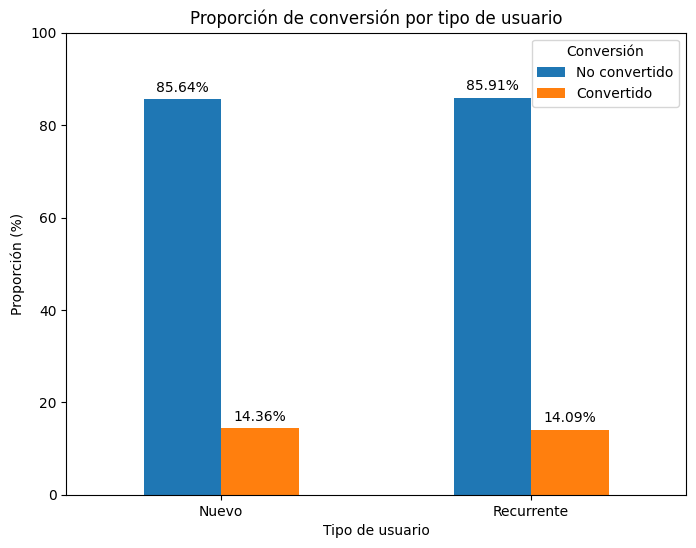

In [353]:
ax = proporcion_usuario.plot(kind="bar", figsize=(8, 6))

plt.title("Proporción de conversión por tipo de usuario")
plt.xlabel("Tipo de usuario")
plt.ylabel("Proporción (%)")
plt.xticks(rotation=0)
plt.legend(
    title="Conversión",
    labels=["No convertido", "Convertido"])

# Etiquetas de porcentaje
for container in ax.containers:
    for bar in container:
        altura = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2,
            altura + 1,
            f"{altura:.2f}%",
            ha="center",
            va="bottom")

plt.ylim(0, 100)
plt.show()

**Conclusión.** Los usuarios nuevos tienen una proporción de conversión ligeramente mayor que los recurrentes (14.36 % contra 14.09 %), pero la diferencia es muy pequeña y visualmente no se nota un comportamiento distinto. Esto es consistente con la prueba chi-cuadrada (p = 0.4736): no hay asociación estadísticamente significativa entre el tipo de usuario y la conversión, así que no parece un factor determinante en este experimento.

Resumen de hallazgos:
- Nuevos: 14.36 % de conversión y 85.64 % de no conversión.
- Recurrentes: 14.09 % de conversión y 85.91 % de no conversión.
- La diferencia es de aproximadamente 0.27 puntos porcentuales.

## Paso 7: Insight ejecutivo para stakeholders

Traduzco los hallazgos del experimento A/B en conclusiones para el negocio, enfocadas en versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario.

**¿Qué página genera mayor conversión y gasto promedio?**
La página B tiene el mejor desempeño en ambos indicadores: conversión de 15.96 % contra 12.57 % de la A, y gasto promedio por usuario convertido de 68.75 contra 61.09. En los dos casos la diferencia es estadísticamente significativa (p < 0.001).

**¿Qué canales de tráfico son más efectivos para generar conversiones?**
Las tasas por fuente fueron Email 14.99 %, Ads 14.74 %, Referral 13.88 % y Organic 13.79 %. La prueba chi-cuadrada mostró una asociación significativa entre la fuente de tráfico y la conversión (p = 0.0341).

**¿Hay diferencias significativas según el tipo de usuario?**
No. Los nuevos convierten 14.36 % y los recurrentes 14.09 %, una diferencia de 0.27 puntos porcentuales (chi-cuadrada, p = 0.4736). El tipo de usuario, por sí solo, no parece un factor determinante de la conversión en este experimento.

**¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?**
Adoptar la página B como versión preferente, por su mejor conversión y gasto promedio; fortalecer las estrategias de Email y Ads, que tienen las tasas más altas; evaluar los canales por volumen y por tasa de conversión, no solo por conversiones absolutas; y no diferenciar la estrategia únicamente entre usuarios nuevos y recurrentes, porque no se encontró diferencia significativa.

### Insight ejecutivo del experimento A/B

#### Comparación de páginas (A vs B)

**Gasto promedio por usuario convertido:** la página A tuvo $61.09 y la B, $68.75. La B genera $7.66 más por usuario convertido que la A, y la diferencia es estadísticamente significativa (p < 0.001), así que hay evidencia para considerarla la alternativa con mejor desempeño en valor generado por conversión.

**Tasa de conversión:** la A alcanzó 12.57 % y la B, 15.96 %. La B supera a la A por 3.39 puntos porcentuales, con diferencia significativa (p < 0.001). Por lo tanto la B rinde mejor tanto en conversión como en gasto promedio.

#### Fuente de tráfico

Email tuvo la mayor tasa de conversión (14.99 %), seguido de Ads (14.74 %), Referral (13.88 %) y Organic (13.79 %). Email y Ads son los canales más eficientes para convertir. Organic genera más conversiones en número por su volumen de usuarios, pero eso no lo hace el canal más eficiente.

#### Tipo de usuario

Los usuarios nuevos convierten 14.36 % y los recurrentes 14.09 %, una diferencia de apenas 0.27 puntos porcentuales. El tipo de usuario no parece influir de forma significativa en la probabilidad de convertir, así que no hay evidencia suficiente para diseñar estrategias distintas solo con base en si el usuario es nuevo o recurrente. Las visualizaciones respaldan los resultados de las pruebas estadísticas.

#### Recomendaciones de negocio

- Implementar la página B como opción preferente, por su mayor conversión y su mayor gasto promedio por usuario convertido, ambos con diferencias estadísticamente significativas.
- Priorizar Email y Ads en la estrategia de adquisición, por tener las tasas de conversión más altas entre las fuentes analizadas.
- No evaluar los canales solo por volumen de conversiones; complementar con la tasa de conversión para identificar los canales realmente eficientes.
- Mantener el seguimiento de usuarios nuevos y recurrentes, pero sin asignar estrategias diferenciadas solo por este criterio, ya que no hay diferencia significativa en conversión.